## 01 · The Grid

Before any AI makes a decision, this notebook shows the system it will be operating: a simulated 50 kW solar-battery-diesel mini-grid serving a rural Nigerian village. No agents yet. Just the sun, the households, and the battery between them.

In [1]:
# Load the simulation environment and plotting tools
import numpy as np
import matplotlib.pyplot as plt
from minigrid_mdp.env.minigrid_env import MiniGridEnv

env = MiniGridEnv()
env.reset(seed=0)

(array([6.9999999e-01, 3.4090367e-03, 1.8797247e+01, 0.0000000e+00,
        0.0000000e+00, 1.0000000e+00, 1.0000000e+00], dtype=float32),
 {})

#### Supply and demand over a day

We sample 200 simulated days and plot the typical solar output and household demand for each hour, with a band showing day-to-day variation.

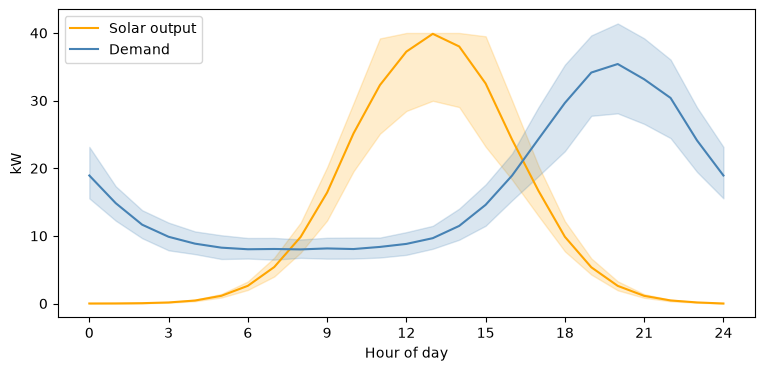

Solar per day: 296 kWh | Demand per day: 395 kWh


In [3]:
# Sample 200 days of hourly PV output and load demand, then plot median and 5–95% band
def sample_days(hourly_fn, n_days=200):
    return np.array([[hourly_fn(h) for h in range(24)] for _ in range(n_days)])

pv = sample_days(env._pv_output)
load = sample_days(env._load_demand)
hours = np.arange(25)

fig, ax = plt.subplots(figsize=(9, 4))
for data, label, color in [(pv, "Solar output", "orange"), (load, "Demand", "steelblue")]:
    data = np.hstack([data, data[:, :1]])  # repeat midnight as 24:00 to close the day
    ax.plot(hours, np.median(data, axis=0), label=label, color=color)
    ax.fill_between(hours, *np.percentile(data, [5, 95], axis=0), color=color, alpha=0.2)
ax.set_xlabel("Hour of day")
ax.set_ylabel("kW")
ax.set_xticks(range(0, 25, 3))
ax.legend()
plt.show()

print(f"Solar per day: {pv.sum(axis=1).mean():.0f} kWh | Demand per day: {load.sum(axis=1).mean():.0f} kWh")

**What this shows:** the village's sun and its demand barely overlap. Solar peaks around 1 pm; households peak around 8 pm, after the sun is gone. Whatever solar isn't used by mid-afternoon has to be stored in the battery or wasted, and every evening kWh the battery can't cover comes from diesel.

## The five choices

Every hour, whoever runs the grid has to decide how to meet demand. In later notebooks that "operator" will be either a fixed rulebook or an AI agent, but the menu is the same for both. There are five choices:

1. **charge_from_diesel**: run the generator and use its spare output to charge the battery
2. **discharge_battery**: serve demand from the battery, generator off
3. **run_diesel_only**: serve demand from the generator
4. **solar_only**: serve demand from solar, with the battery absorbing surplus or covering gaps
5. **shed_load**: cut households down to essential load only

The names are shorthand, so the table below tests each choice in three situations and records where the energy really goes.

How to read the table: `battery_kw` is positive when the battery is discharging and negative when it is charging. `curtailed_kw` means wasted solar for most choices, but households cut off for `shed_load`.

In [4]:
# Run each action through three test situations and tabulate the resulting energy flows (kW)
import pandas as pd

ACTION_NAMES = ["charge_from_diesel", "discharge_battery", "run_diesel_only", "solar_only", "shed_load"]
SCENARIOS = {
    "Sunny noon":                  dict(soc=0.5, pv_kw=40.0, load_kw=9.0),
    "Evening peak":                dict(soc=0.5, pv_kw=0.0,  load_kw=35.0),
    "Evening peak, empty battery": dict(soc=0.2, pv_kw=0.0,  load_kw=35.0),
}
FLOW_COLUMNS = ["diesel_kw", "battery_kw", "unmet_load_kw", "curtailed_kw"]

def flows_for(env, soc, pv_kw, load_kw, action):
    env._soc = soc
    flows = env._dispatch(action, pv_kw, load_kw, hour=0)
    return {col: round(flows[col], 1) for col in FLOW_COLUMNS}

rows = [
    {"scenario": name, "action": ACTION_NAMES[a], **flows_for(env, **cfg, action=a)}
    for name, cfg in SCENARIOS.items()
    for a in range(len(ACTION_NAMES))
]
action_table = pd.DataFrame(rows).set_index(["scenario", "action"])
env.reset(seed=0)
action_table

diesel_kw  battery_kw  \
scenario                    action                                      
Sunny noon                  charge_from_diesel       18.0       -30.0   
                            discharge_battery         0.0         0.0   
                            run_diesel_only           9.0       -30.0   
                            solar_only                0.0       -30.0   
                            shed_load                 0.0         0.0   
Evening peak                charge_from_diesel       30.0         5.0   
                            discharge_battery         0.0        30.0   
                            run_diesel_only          30.0         5.0   
                            solar_only                0.0        30.0   
                            shed_load                 0.0         8.0   
Evening peak, empty battery charge_from_diesel       30.0         0.0   
                            discharge_battery         0.0         0.0   
                            run_diesel_only          30.0         0.0   
                            solar_only                0.0         0.0   
                            shed_load                 0.0         0.0   

                                                unmet_load_kw  curtailed_kw  
scenario                    action                                           
Sunny noon                  charge_from_diesel            0.0           0.0  
                            discharge_battery             0.0           0.0  
                            run_diesel_only               0.0          10.0  
                            solar_only                    0.0           1.0  
                            shed_load                     0.0           1.0  
Evening peak                charge_from_diesel            0.0           0.0  
                            discharge_battery             5.0           0.0  
                            run_diesel_only               0.0           0.0  
                            solar_only                    5.0           0.0  
                            shed_load                     0.0          27.0  
Evening peak, empty battery charge_from_diesel            5.0           0.0  
                            discharge_battery            35.0           0.0  
                            run_diesel_only               5.0           0.0  
                            solar_only                   35.0           0.0  
                            shed_load                     8.0          27.0

**What this shows:**

- **Diesel can't cover the peak alone.** The generator tops out at 30 kW, below the 35 kW evening peak. Even running flat out, it needs the battery to fill the gap, and with an empty battery that gap becomes unmet demand.
- **The battery is the only bridge from afternoon to evening**, and it only charges from surplus solar under `solar_only` or `run_diesel_only`, or from diesel under `charge_from_diesel`.
- **Some actions waste solar without recording it.** At noon, `discharge_battery` and `shed_load` neither store nor log the surplus. This doesn't affect costs, since wasted solar isn't priced, but it means the logs undercount curtailment.

## One day without diesel

To see what the battery can do on its own, we run a single day choosing `solar_only` every hour: solar serves demand, surplus charges the battery, and the battery covers shortfalls until it hits its 20% floor. No diesel at all.

In [5]:
# Simulate one day choosing solar_only every hour, then collect the step log
from minigrid_mdp.env.minigrid_env import ACTION_SOLAR_ONLY

def run_fixed_day(env, action, seed=0):
    env.reset(seed=seed)
    for _ in range(env.ep_len):
        env.step(action)
    return env.log_as_dataframe()

day = run_fixed_day(env, ACTION_SOLAR_ONLY)

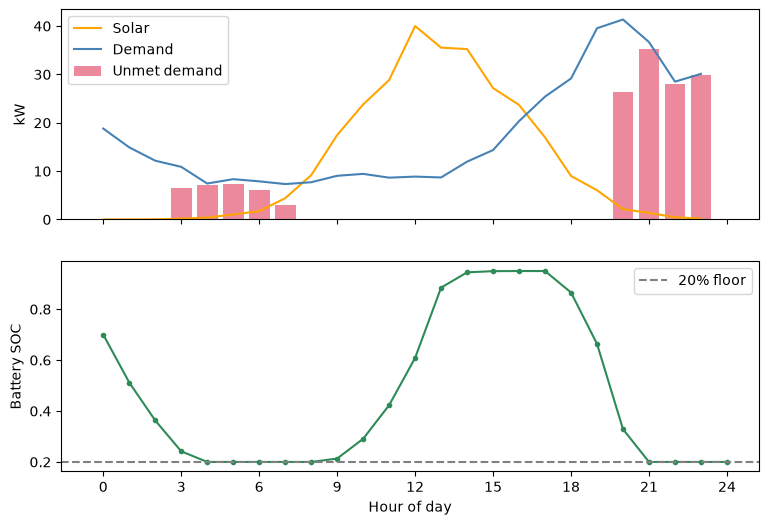

Unmet demand: 150 kWh | Wasted solar: 60 kWh | End SOC: 0.20


In [6]:
# Plot power flows (top) and battery state of charge (bottom) across the day
fig, (ax_power, ax_soc) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax_power.plot(day.hour, day.pv_kw, label="Solar", color="orange")
ax_power.plot(day.hour, day.load_kw, label="Demand", color="steelblue")
ax_power.bar(day.hour, day.unmet_load_kw, label="Unmet demand", color="crimson", alpha=0.5)
ax_power.set_ylabel("kW")
ax_power.legend()

soc_curve = [env.bat_cfg["initial_soc"]] + day.soc_after.tolist()
ax_soc.plot(range(25), soc_curve, color="seagreen", marker="o", markersize=3)
ax_soc.axhline(env.bat_cfg["min_soc"], color="gray", linestyle="--", label="20% floor")
ax_soc.set_ylabel("Battery SOC")
ax_soc.set_xlabel("Hour of day")
ax_soc.set_xticks(range(0, 25, 3))
ax_soc.legend()
plt.show()

print(f"Unmet demand: {day.unmet_load_kw.sum():.0f} kWh | Wasted solar: {day.curtailed_kw.sum():.0f} kWh | End SOC: {day.soc_after.iloc[-1]:.2f}")

**What this shows:** without diesel, the village goes without power for 150 kWh of its 396 kWh daily demand, mostly during the evening peak. The battery empties overnight, refills by early afternoon, then sits full while about 60 kWh of solar is wasted. The constraint isn't sunshine. It's storage: the battery can hold about 75 usable kWh, while the evening alone needs around 230. Diesel has to fill the gap; the question for the next notebooks is how much diesel, and when.

## Summary

- The simulated grid has a 50 kW solar array (≈ 295 kWh/day), a 100 kWh battery (75 kWh usable) and a 30 kW diesel generator, serving demand of ≈ 396 kWh/day that peaks at 8 pm.
- Solar and demand barely overlap, so the battery has to carry solar energy from afternoon into evening, and it isn't big enough to carry all of it.
- The diesel generator alone can't cover the 35 kW evening peak either; at peak it needs the battery's help.

**Next:** notebook 02 introduces the first operator, a fixed rulebook, and measures how much diesel it burns to keep the lights on.